# House Prices Prediction Using Principal Component Analysis (PCA)

## Project Overview

This project explores the application of Principal Component Analysis (PCA) to dimensionality reduction in house price prediction.

The objective is to investigate whether PCA can reduce the number of input features while preserving useful information and maintaining competitive regression performance.

The project includes:

- Exploratory Data Analysis (EDA)
- Data Cleaning and Preprocessing
- Handling Missing Values
- Encoding Categorical Features
- Feature Scaling
- Principal Component Analysis (PCA)
- Regression Model Training
- Performance Comparison With and Without PCA
- Model Evaluation and Interpretation

**Target Variable:** SalePrice

**Problem Type:** Supervised Learning — Regression

**Main Technique:** Principal Component Analysis (PCA)

----

This project focuses on comparing regression performance with and without PCA rather than maximizing house price prediction accuracy.

## Import Liraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


## Load Dataset

In [2]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Training Dataset:", train_df.shape)
print("Kaggle Test Dataset:", test_df.shape)

display(train_df.head())

Training Dataset: (1460, 81)
Kaggle Test Dataset: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Initial Data Inspection

In [3]:
print("Dataset Information:")
train_df.info()

print("\nMissing Values:")
print(train_df.isnull().sum().sort_values(ascending=False).head(20))

print("\nDuplicate Rows:", train_df.duplicated().sum())

print("\nTarget Statistics:")
display(train_df['SalePrice'].describe())

print("\nData Types:")
print(train_df.dtypes.value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


Data Types:
str        43
int64      35
float64     3
Name: count, dtype: int64


### Initial Data Inspection — Findings

- The training dataset contains 1,460 observations and 81 columns, including the target variable, SalePrice.

- The dataset includes 35 integer columns, 3 floating-point columns, and 43 string columns.

- No duplicate rows were detected.

- Several features contain substantial missing values, including PoolQC, MiscFeature, Alley, Fence, MasVnrType, and FireplaceQu.

- Some missing values represent the absence of a property feature, such as a garage, basement, or swimming pool, rather than an unknown measurement.

- Therefore, missing values will be investigated before selecting appropriate imputation strategies.

- Since the dataset contains both numerical and categorical variables, preprocessing will be required before applying Principal Component Analysis (PCA).### Initial Data Inspection — Findings

- The training dataset contains 1,460 observations and 81 columns, including the target variable, SalePrice.

- The dataset includes 35 integer columns, 3 floating-point columns, and 43 string columns.

- No duplicate rows were detected.

- Several features contain substantial missing values, including PoolQC, MiscFeature, Alley, Fence, MasVnrType, and FireplaceQu.

- Some missing values represent the absence of a property feature, such as a garage, basement, or swimming pool, rather than an unknown measurement.

- Therefore, missing values will be investigated before selecting appropriate imputation strategies.

- Since the dataset contains both numerical and categorical variables, preprocessing will be required before applying Principal Component Analysis (PCA).

## Exploratory Data Analysis (EDA)

### Target Variable Analysis

The target variable, SalePrice, represents the final selling price of each property.

The analysis examines its distribution, central tendency, variability, skewness, and potential outliers.

Understanding the target distribution helps identify whether transformations may be useful for regression modeling.

In [4]:
print("SalePrice Descriptive Statistics:")
display(train_df['SalePrice'].describe())

print("\nSkewness:",
      round(train_df['SalePrice'].skew(), 4))

print("\nKurtosis:",
      round(train_df['SalePrice'].kurt(), 4))

SalePrice Descriptive Statistics:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


Skewness: 1.8829

Kurtosis: 6.5363


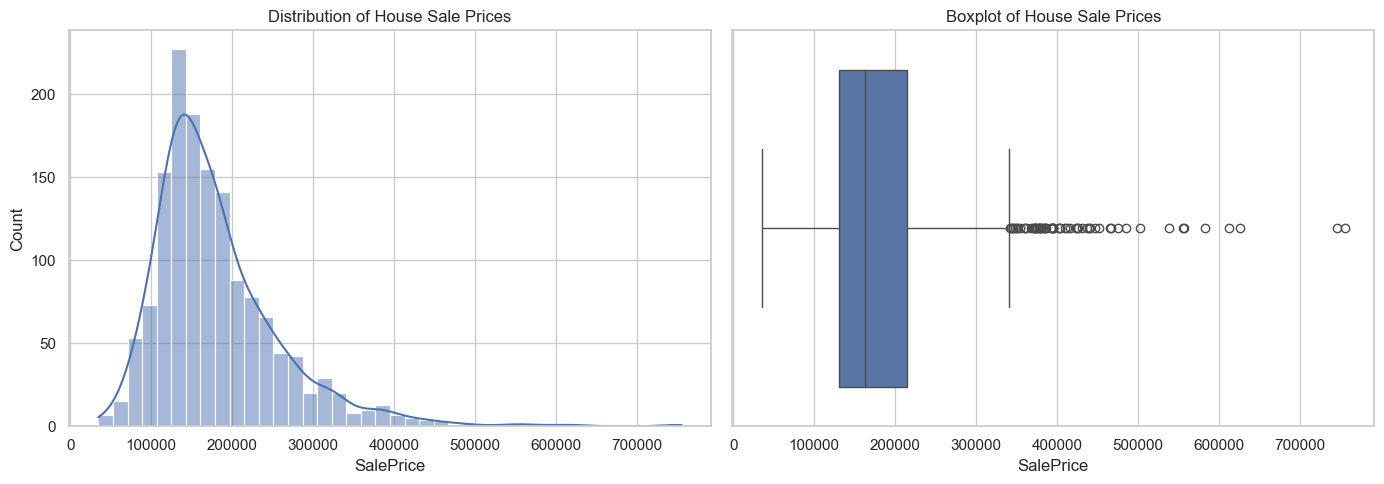

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train_df['SalePrice'], bins=40, kde=True, ax=axes[0])

axes[0].set_title('Distribution of House Sale Prices')
axes[0].set_xlabel('SalePrice')

sns.boxplot(x=train_df['SalePrice'], ax=axes[1])

axes[1].set_title('Boxplot of House Sale Prices')
axes[1].set_xlabel('SalePrice')

plt.tight_layout()
plt.show()

### SalePrice Distribution — Findings

The SalePrice variable contains 1,460 observations, with a mean of approximately $180,921 and a median of $163,000.

The mean exceeds the median, indicating a positively skewed distribution.

Most house prices are concentrated in the lower-to-middle price ranges, while a smaller number of expensive properties create a long right tail.

The boxplot reveals several potential high-price outliers. However, these observations are not necessarily errors and will not be removed automatically.

A logarithmic transformation of SalePrice will be investigated to assess whether it produces a more symmetric target distribution.

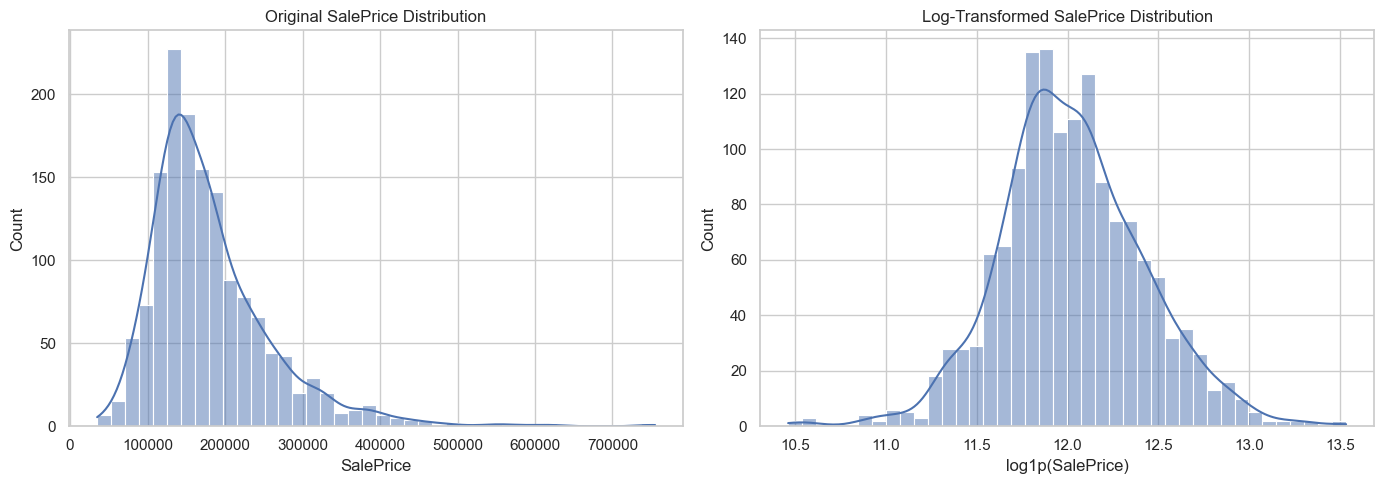

In [6]:
# Create a temporary log-transformed target for EDA
saleprice_log = np.log1p(train_df['SalePrice'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    train_df['SalePrice'],
    bins=40,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Original SalePrice Distribution')
axes[0].set_xlabel('SalePrice')

sns.histplot(
    saleprice_log,
    bins=40,
    kde=True,
    ax=axes[1]
)

axes[1].set_title('Log-Transformed SalePrice Distribution')
axes[1].set_xlabel('log1p(SalePrice)')

plt.tight_layout()
plt.show()

In [7]:
distribution_comparison = pd.DataFrame({
    'Original SalePrice': [
        train_df['SalePrice'].skew(),
        train_df['SalePrice'].kurt()
    ],
    'Log-Transformed SalePrice': [
        saleprice_log.skew(),
        saleprice_log.kurt()
    ]
}, index=['Skewness', 'Kurtosis'])

display(distribution_comparison.round(4))

,Original SalePrice,Log-Transformed SalePrice
Skewness,1.8829,0.1213
Kurtosis,6.5363,0.8095


### Log Transformation — Findings

The original SalePrice distribution was strongly right-skewed, with a skewness of 1.8829 and excess kurtosis of 6.5363.

After applying log1p(SalePrice), skewness decreased to 0.1213 and excess kurtosis decreased to 0.8095.

The transformed distribution appeared substantially more symmetric, with a reduced right tail.

Based on these findings, log1p(SalePrice) was selected as the initial target transformation for regression modeling.

Predictions will be transformed back to the original price scale using expm1() before calculating MAE, RMSE, and R².

Improved distributional symmetry does not necessarily guarantee better predictive performance.

## Numerical Feature Analysis

### Correlation with SalePrice

Pearson correlation is used to examine linear relationships between numerical features and the target variable.

Correlation measures association, not causation.

The analysis is exploratory and will not be used to select features using the held-out test data.

In [8]:
# Numerical columns excluding the identifier
numeric_df = train_df.select_dtypes(include=['int64', 'float64']).drop(columns=['Id'])

# Correlation with SalePrice
price_correlations = (
    numeric_df.corr()['SalePrice']
    .drop('SalePrice')
    .sort_values(ascending=False))

print("Top 10 Positive Correlations:")
display(price_correlations.head(10).round(4))

print("\nTop 10 Negative Correlations:")
display(price_correlations.tail(10).round(4))

Top 10 Positive Correlations:


OverallQual     0.7910
GrLivArea       0.7086
GarageCars      0.6404
GarageArea      0.6234
TotalBsmtSF     0.6136
1stFlrSF        0.6059
FullBath        0.5607
TotRmsAbvGrd    0.5337
YearBuilt       0.5229
YearRemodAdd    0.5071
Name: SalePrice, dtype: float64


Top 10 Negative Correlations:


3SsnPorch        0.0446
BsmtFinSF2      -0.0114
BsmtHalfBath    -0.0168
MiscVal         -0.0212
LowQualFinSF    -0.0256
YrSold          -0.0289
OverallCond     -0.0779
MSSubClass      -0.0843
EnclosedPorch   -0.1286
KitchenAbvGr    -0.1359
Name: SalePrice, dtype: float64

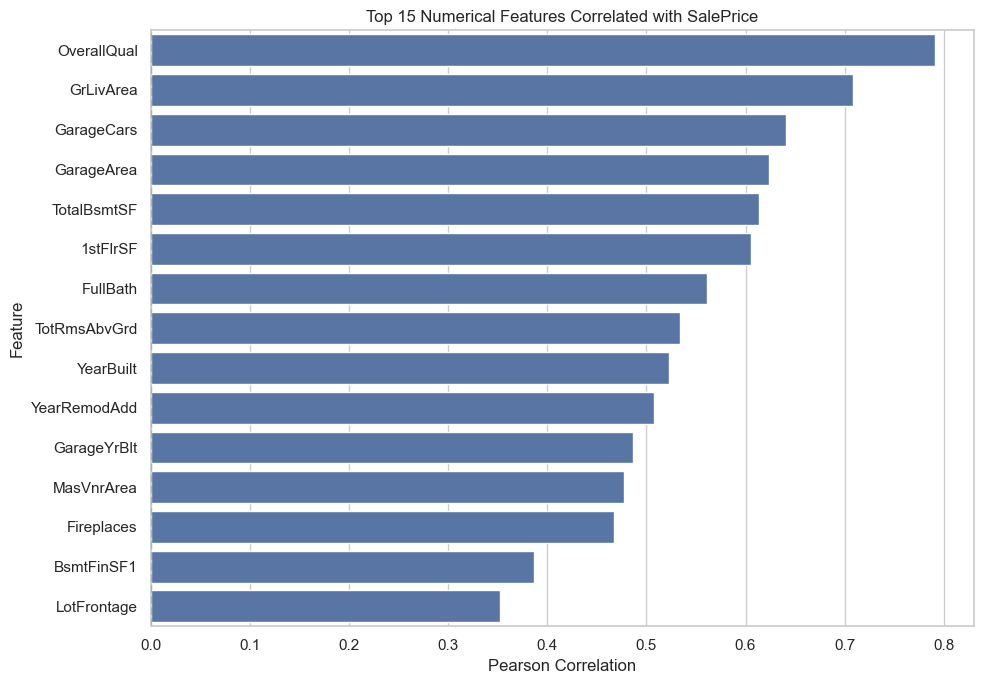

In [9]:
top_features = (price_correlations.abs().sort_values(ascending=False).head(15).index)

plt.figure(figsize=(10, 7))

sns.barplot(x=price_correlations.loc[top_features].values,y=top_features)

plt.axvline(0, color='black', linestyle='--')

plt.title('Top 15 Numerical Features Correlated with SalePrice')
plt.xlabel('Pearson Correlation')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

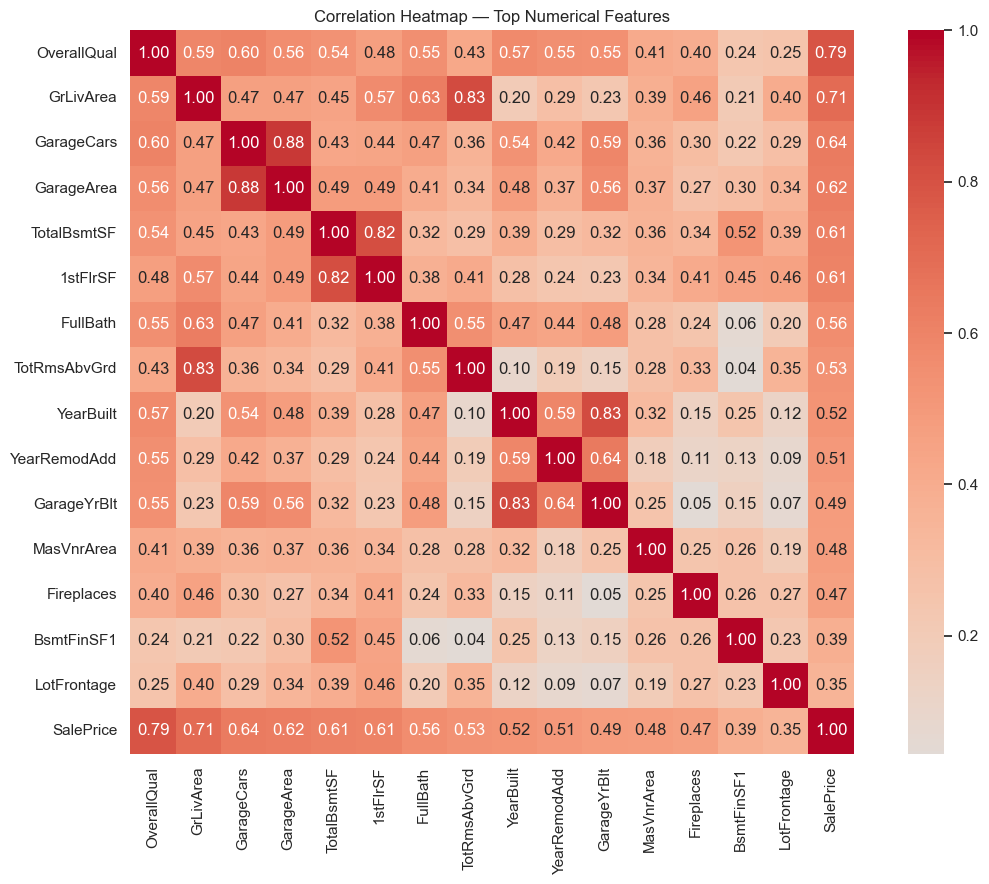

In [10]:
selected_columns = list(top_features) + ['SalePrice']

corr_matrix = numeric_df[selected_columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(corr_matrix,annot=True,fmt='.2f',cmap='coolwarm',center=0,square=True)

plt.title('Correlation Heatmap — Top Numerical Features')

plt.tight_layout()
plt.show()

### Numerical Feature Analysis — Findings

Pearson correlation analysis identified OverallQual (r = 0.7910) and GrLivArea (r = 0.7086) as the numerical features most strongly associated with SalePrice.

Other positively correlated features included GarageCars, GarageArea, TotalBsmtSF, and 1stFlrSF.

The correlation heatmap also revealed strong relationships between several predictor variables:

- GarageCars and GarageArea: r = 0.88
- GrLivArea and TotRmsAbvGrd: r = 0.83
- YearBuilt and GarageYrBlt: r = 0.83
- TotalBsmtSF and 1stFlrSF: r = 0.82

These relationships suggest that some predictors contain overlapping information, motivating the investigation of Principal Component Analysis (PCA) for dimensionality reduction.

The observed correlations describe linear associations and do not establish causation.

No features were removed solely on the basis of these exploratory correlations.

## Categorical Feature Analysis

This section explores the relationship between categorical property characteristics and SalePrice.

Selected categorical features are analyzed using group-level median sale prices and boxplots.

The analysis focuses on Neighborhood, ExterQual, KitchenQual, HouseStyle, and CentralAir.

These exploratory comparisons help identify potential differences in house prices across categories.

Categorical variables will be encoded appropriately during preprocessing before PCA is applied.

In [11]:
categorical_features = [
    'Neighborhood',
    'ExterQual',
    'KitchenQual',
    'HouseStyle',
    'CentralAir'
]

for feature in categorical_features:
    print(f"\n{feature} — SalePrice Summary")

    summary = (
        train_df.groupby(feature, dropna=False)['SalePrice']
        .agg(['count', 'mean', 'median'])
        .sort_values('median', ascending=False)
    )

    display(summary.round(2))


Neighborhood — SalePrice Summary


,count,mean,median
Neighborhood,,,
NridgHt,77,316270.62,315000.0
NoRidge,41,335295.32,301500.0
StoneBr,25,310499.00,278000.0
Timber,38,242247.45,228475.0
Somerst,86,225379.84,225500.0
Veenker,11,238772.73,218000.0
Crawfor,51,210624.73,200624.0
ClearCr,28,212565.43,200250.0
CollgCr,150,197965.77,197200.0



ExterQual — SalePrice Summary


,count,mean,median
ExterQual,,,
Ex,52,367360.96,364606.5
Gd,488,231633.51,220000.0
TA,906,144341.31,139450.0
Fa,14,87985.21,82250.0



KitchenQual — SalePrice Summary


,count,mean,median
KitchenQual,,,
Ex,100,328554.67,316750.0
Gd,586,212116.02,201400.0
TA,735,139962.51,137000.0
Fa,39,105565.21,115000.0



HouseStyle — SalePrice Summary


,count,mean,median
HouseStyle,,,
2.5Fin,8,220000.00,194000.0
2Story,445,210051.76,190000.0
SLvl,65,166703.38,164500.0
1Story,726,175985.48,154750.0
SFoyer,37,135074.49,135960.0
2.5Unf,11,157354.55,133900.0
1.5Fin,154,143116.74,132000.0
1.5Unf,14,110150.00,111250.0



CentralAir — SalePrice Summary


,count,mean,median
CentralAir,,,
Y,1365,186186.71,168000.0
N,95,105264.07,98000.0


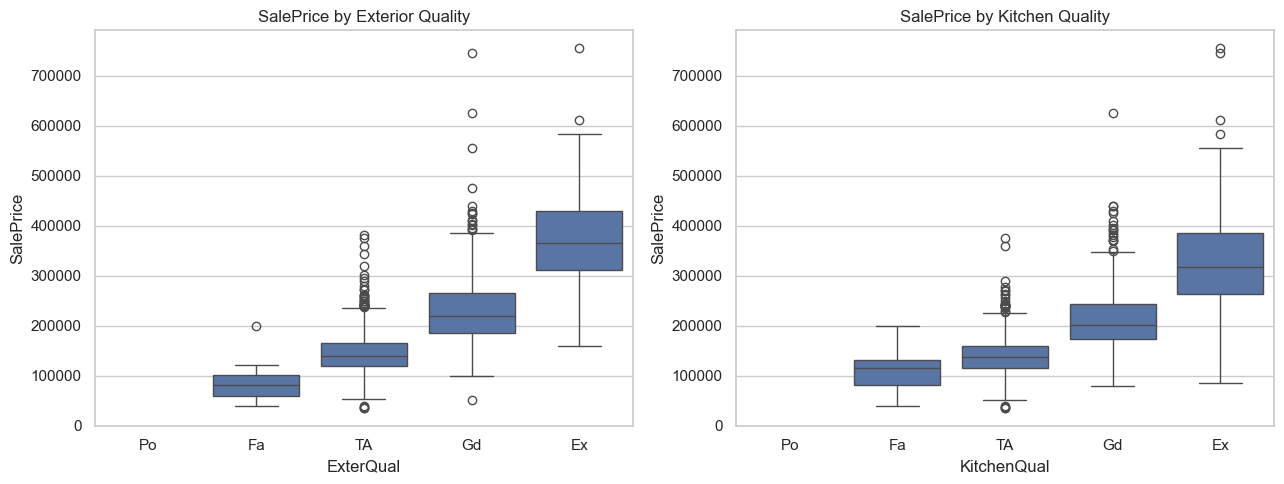

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

quality_order = ['Po', 'Fa', 'TA', 'Gd', 'Ex']

sns.boxplot(
    data=train_df,
    x='ExterQual',
    y='SalePrice',
    order=quality_order,
    ax=axes[0]
)

axes[0].set_title('SalePrice by Exterior Quality')

sns.boxplot(
    data=train_df,
    x='KitchenQual',
    y='SalePrice',
    order=quality_order,
    ax=axes[1]
)

axes[1].set_title('SalePrice by Kitchen Quality')

plt.tight_layout()
plt.show()

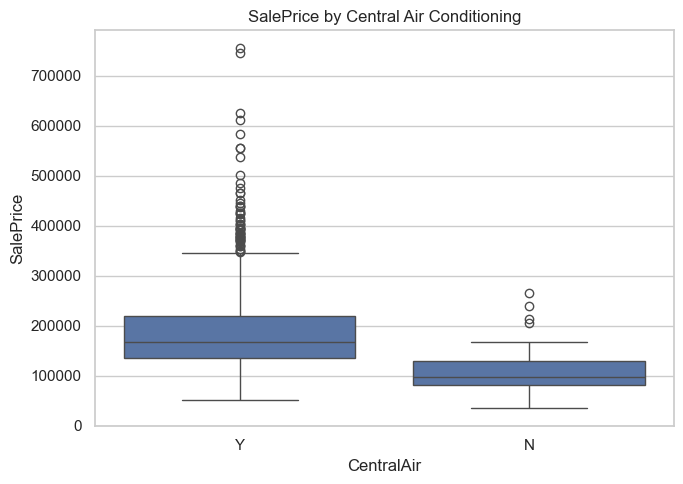

In [13]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=train_df,x='CentralAir',y='SalePrice')

plt.title('SalePrice by Central Air Conditioning')
plt.xlabel('CentralAir')
plt.ylabel('SalePrice')

plt.tight_layout()
plt.show()

### Categorical Feature Analysis — Findings

Categorical feature analysis revealed substantial differences in house sale prices across neighborhoods, property quality levels, and housing characteristics.

Neighborhood showed considerable variation in median SalePrice. NridgHt had the highest median price of $315,000, while MeadowV had the lowest median price of $88,000.

Exterior quality and kitchen quality showed clear positive associations with house prices. Properties classified as Excellent generally had higher median prices than those classified as Good, Typical, or Fair.

HouseStyle also showed variation in sale prices, although some categories contained relatively few observations.

Properties with central air conditioning had a median SalePrice of $168,000, compared with $98,000 for properties without central air conditioning.

These results suggest that categorical property characteristics contain potentially useful predictive information.

However, the observed relationships are descriptive and do not establish causation.

Categorical features will be encoded during preprocessing before applying PCA.

## Data Splitting and Preprocessing

The labeled dataset is divided into training (80%) and validation (20%) subsets using a reproducible random split.

The Id column is excluded because it is a record identifier rather than a meaningful property characteristic.

The target variable is transformed using log1p(SalePrice) for regression modeling.

All preprocessing operations, including missing-value imputation, categorical encoding, feature scaling, and PCA, will be fitted exclusively on the training data.

The validation set will be used to compare regression models with and without PCA.

The separate Kaggle test dataset will be reserved for generating final predictions.

In [14]:
X = train_df.drop(columns=['Id', 'SalePrice'])

y = np.log1p(train_df['SalePrice'])

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (1168, 79)
X_val: (292, 79)
y_train: (1168,)
y_val: (292,)


In [15]:
X_train = X_train.copy()
X_val = X_val.copy()

X_train['MSSubClass'] = X_train['MSSubClass'].astype(str)
X_val['MSSubClass'] = X_val['MSSubClass'].astype(str)

numerical_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'str', 'category']
).columns.tolist()

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

print("\nNumerical Columns:")
print(numerical_features)

print("\nCategorical Columns:")
print(categorical_features)

Numerical Features: 35
Categorical Features: 44

Numerical Columns:
['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']

Categorical Columns:
['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'Kitchen

### Preprocessing Pipeline

Numerical features are processed using median imputation followed by standardization.

Categorical features are processed using most-frequent imputation followed by one-hot encoding.

One-hot encoding allows categorical variables to be represented numerically without imposing an arbitrary order on nominal categories.

Preprocessing is fitted on the training set only to avoid data leakage.

The same fitted transformations are then applied to validation observations.

The resulting feature matrix will be used for both baseline regression and PCA-based regression experiments.

In [16]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [17]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

print("Original Training Shape:", X_train.shape)
print("Processed Training Shape:", X_train_processed.shape)

print("\nOriginal Validation Shape:", X_val.shape)
print("Processed Validation Shape:", X_val_processed.shape)

print("\nMissing Values After Preprocessing:",
      np.isnan(X_train_processed).sum())

Original Training Shape: (1168, 79)
Processed Training Shape: (1168, 299)

Original Validation Shape: (292, 79)
Processed Validation Shape: (292, 299)

Missing Values After Preprocessing: 0


### Preprocessing Results

The original dataset contained 79 input features after excluding Id and SalePrice.

Following numerical imputation, standardization, categorical imputation, and one-hot encoding, the feature space increased to 299 dimensions.

The processed training set contains 1,168 observations and 299 features, while the processed validation set contains 292 observations and 299 features.

No missing values remained in the processed training data.

All preprocessing transformations were fitted exclusively on the training set to prevent data leakage.

Principal Component Analysis (PCA) will now be investigated to reduce the dimensionality of the processed feature space.

## Principal Component Analysis (PCA)

Principal Component Analysis is an unsupervised dimensionality reduction technique that transforms the original features into a new set of orthogonal variables called principal components.

The first principal component captures the maximum possible variance in the data. Each subsequent component captures the maximum remaining variance while being orthogonal to the preceding components.

PCA can help reduce feature dimensionality and summarize correlated information.

In this project, PCA is applied to the preprocessed training data to investigate how many components are needed to preserve 90% and 95% of the total variance.

PCA is fitted exclusively on the training set to prevent data leakage.

In [18]:
pca_full= PCA()
pca_full.fit(X_train_processed)
explained_variance_ratio = pca_full.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance_ratio)

print("Number of Original Features:", X_train_processed.shape[1])
print("Number of Principal Components:", len(explained_variance_ratio))

print("\nExplained Variance by First 10 Components:")
display(
    pd.DataFrame({
        'Component': np.arange(1, 11),
        'Explained Variance Ratio': explained_variance_ratio[:10],
        'Cumulative Explained Variance': cumulative_variance[:10]
    }).round(4)
)

Number of Original Features: 299
Number of Principal Components: 299

Explained Variance by First 10 Components:


,Component,Explained Variance Ratio,Cumulative Explained Variance
0,1,0.1683,0.1683
1,2,0.0754,0.2437
2,3,0.0650,0.3087
3,4,0.0441,0.3528
4,5,0.0303,0.3830
5,6,0.0272,0.4102
6,7,0.0251,0.4353
7,8,0.0242,0.4595
8,9,0.0234,0.4829
9,10,0.0229,0.5058


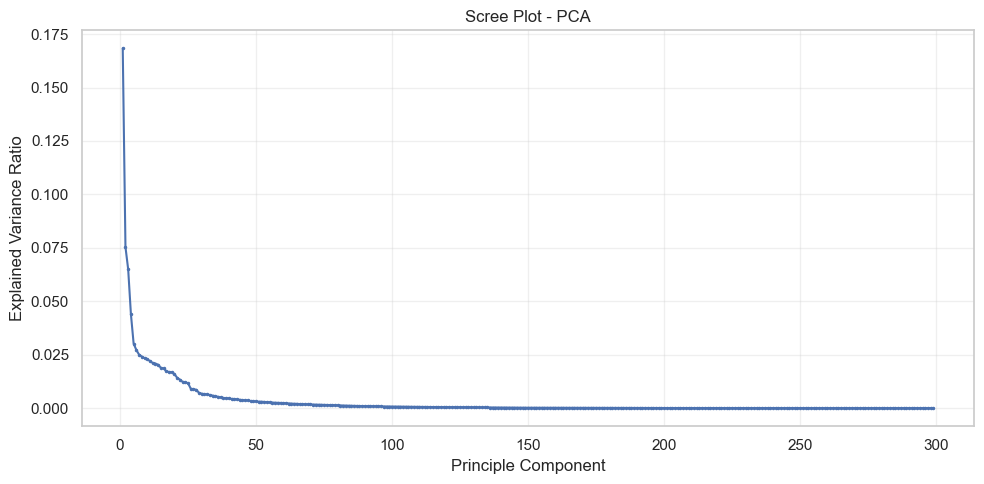

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(
    range(1, len(explained_variance_ratio) + 1),
    explained_variance_ratio,
    marker='.',
    markersize=3)
plt.xlabel('Principle Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot - PCA')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

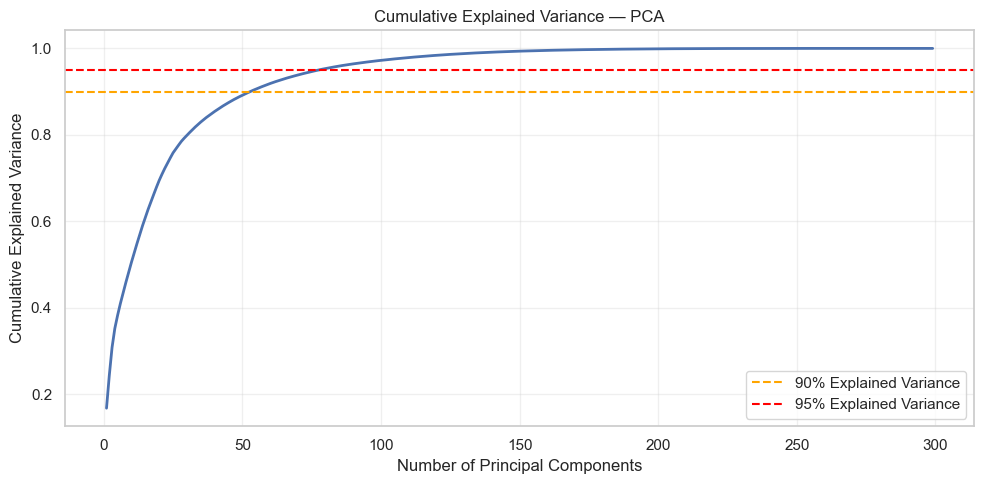

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2)

plt.axhline(y=0.90, color='orange', linestyle='--', label='90% Explained Variance')

plt.axhline(y=0.95, color='red', linestyle='--', label='95% Explained Variance')

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance — PCA')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
n_components_90 = np.searchsorted(cumulative_variance, 0.90) + 1

n_components_95 = np.searchsorted(cumulative_variance, 0.95) + 1

print("Original Number of Features:", X_train_processed.shape[1])

print("Components for 90% Variance:", n_components_90)
print("Components for 95% Variance:", n_components_95)

print(
    "Dimensionality Reduction at 90%:",
    f"{(1 - n_components_90 / X_train_processed.shape[1]) * 100:.2f}%")

print(
    "Dimensionality Reduction at 95%:",
    f"{(1 - n_components_95 / X_train_processed.shape[1]) * 100:.2f}%")

Original Number of Features: 299
Components for 90% Variance: 53
Components for 95% Variance: 78
Dimensionality Reduction at 90%: 82.27%
Dimensionality Reduction at 95%: 73.91%


### PCA Explained Variance — Findings

After preprocessing, the dataset contained 299 numerical features.

Principal Component Analysis (PCA) was fitted exclusively on the training data to investigate dimensionality reduction.

The first principal component explained 16.83% of the total variance, while the first ten components explained approximately 50.58%.

The analysis showed that:

- 53 principal components preserved at least 90% of the total variance.
- 78 principal components preserved at least 95% of the total variance.
- Using 53 components reduced dimensionality by 82.27%.
- Using 78 components reduced dimensionality by 73.91%.

The scree plot showed that the earliest principal components captured relatively large proportions of variance, while later components contributed progressively smaller amounts.

The cumulative explained variance plot demonstrated that substantial dimensionality reduction was possible.

However, preserving variance does not necessarily preserve all information relevant to predicting SalePrice.

Therefore, regression models with and without PCA will be compared to evaluate the impact of dimensionality reduction on predictive performance.

## Regression Modeling — With and Without PCA

This section evaluates the effect of PCA on house price prediction using Ridge Regression.

Three configurations are compared:

1. Ridge Regression without PCA.
2. Ridge Regression with PCA retaining 90% of variance.
3. Ridge Regression with PCA retaining 95% of variance.

Each model uses the same training and validation subsets.

Preprocessing and PCA are included inside scikit-learn Pipelines to prevent data leakage.

The target variable is log-transformed during training, and predictions are converted back to the original price scale for evaluation.

Performance is evaluated using MAE, RMSE, and R².

In [22]:
from sklearn.base import clone

# Model 1: Ridge without PCA
ridge_baseline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('regressor', Ridge(alpha=1.0))
])

# Model 2: Ridge with PCA 90% explained variance
ridge_pca_90 = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('pca', PCA(n_components=0.90)),
    ('regressor', Ridge(alpha=1.0))
])

# Model 3: Ridge with PCA 95% explained variance
ridge_pca_95 = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('pca', PCA(n_components=0.95)),
    ('regressor', Ridge(alpha=1.0))
])

print("All regression pipelines created successfully!")

All regression pipelines created successfully!


In [24]:
models = {
    'Ridge Baseline' : ridge_baseline,
    'Ridge + PCA 90%' : ridge_pca_90,
    'Ridge + PCA 95%' : ridge_pca_95,
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully")

Ridge Baseline trained successfully
Ridge + PCA 90% trained successfully
Ridge + PCA 95% trained successfully


In [25]:
y_val_original = np.expm1(y_val)
results = []
for name, model in models.items():
    
    # Predictions on log scale
    y_pred_log = model.predict(X_val)

    # Convert predictions to original price scale
    y_pred = np.expm1(y_pred_log)

    mae = mean_absolute_error(y_val_original, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val_original, y_pred))
    r2 = r2_score(y_val_original, y_pred)
    
    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values('RMSE').round(4))

,Model,MAE,RMSE,R2
0,Ridge Baseline,16034.2509,24228.6440,0.9235
2,Ridge + PCA 95%,18161.7082,27752.6427,0.8996
1,Ridge + PCA 90%,18381.9887,28664.3958,0.8929


In [26]:
print("PCA 90% Components:",
    ridge_pca_90.named_steps['pca'].n_components_)

print("PCA 95% Components:",
    ridge_pca_95.named_steps['pca'].n_components_)

PCA 90% Components: 53
PCA 95% Components: 78


### Regression Performance Comparison — Findings

Three Ridge Regression configurations were evaluated on the same validation set:

1. Ridge Regression without PCA.
2. Ridge Regression with PCA retaining 90% of explained variance.
3. Ridge Regression with PCA retaining 95% of explained variance.

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Ridge Baseline | 16034.25 | 24228.64 | 0.9235 |
| Ridge + PCA 95% | 18161.71 | 27752.64 | 0.8996 |
| Ridge + PCA 90% | 18381.99 | 28664.40 | 0.8929 |

The baseline Ridge Regression model achieved the best predictive performance.

Although PCA substantially reduced the feature space, both PCA-based configurations produced higher prediction errors.

Compared with the baseline, RMSE increased by approximately 14.54% with PCA 95% and 18.31% with PCA 90%.

This suggests that some information discarded during dimensionality reduction may have been useful for predicting house prices.

PCA maximizes retained feature variance rather than predictive relevance to the target variable.

Furthermore, Ridge Regression already uses L2 regularization, which can help manage correlated predictors.

Overall, PCA provided dimensionality reduction but did not improve validation performance in this experiment.

## PCA Component Sensitivity Analysis

This experiment investigates how different PCA explained-variance thresholds affect Ridge Regression performance.

PCA configurations retaining 70%, 80%, 85%, 90%, 95%, and 99% of the total variance are evaluated.

The objective is to examine the trade-off between dimensionality reduction and predictive accuracy.

All preprocessing and PCA transformations are fitted exclusively on the training data.

Validation results are used for exploratory comparison rather than as a substitute for cross-validation.

In [27]:
variance_thresholds = [0.70, 0.80, 0.85, 0.90, 0.95, 0.99]

pca_results = []

for threshold in variance_thresholds:
    model = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('pca', PCA(n_components=threshold)),
        ('regressor', Ridge(alpha=1.0))
    ])

    model.fit(X_train, y_train)

    y_pred_log = model.predict(X_val)
    y_pred = np.expm1(y_pred_log)

    pca_results.append({
        'Explained Variance': threshold,
        'Components': model.named_steps['pca'].n_components_,
        'MAE': mean_absolute_error(y_val_original, y_pred),
        'RMSE': np.sqrt(
            mean_squared_error(y_val_original, y_pred)
        ),
        'R2': r2_score(y_val_original, y_pred)
    })

pca_sensitivity_df = pd.DataFrame(pca_results)

display(pca_sensitivity_df.round(4))

,Explained Variance,Components,MAE,RMSE,R2
0,0.70,21,18889.3915,29676.1790,0.8852
1,0.80,31,19624.0552,31019.6284,0.8746
2,0.85,40,19138.6627,30615.5478,0.8778
3,0.90,53,18381.9887,28664.3958,0.8929
4,0.95,78,18161.7082,27752.6427,0.8996
5,0.99,136,17216.0573,25983.6219,0.9120


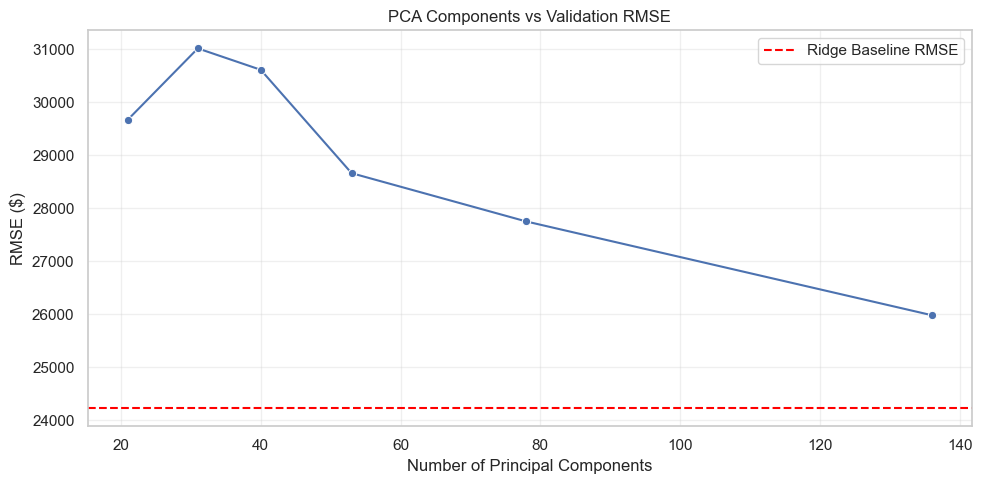

In [29]:
plt.figure(figsize=(10, 5))

sns.lineplot(data=pca_sensitivity_df,x='Components',y='RMSE',marker='o')

plt.axhline(
    y=results_df.loc[
        results_df['Model'] == 'Ridge Baseline', 'RMSE'
    ].iloc[0],
    color='red',
    linestyle='--',
    label='Ridge Baseline RMSE'
)

plt.title('PCA Components vs Validation RMSE')
plt.xlabel('Number of Principal Components')
plt.ylabel('RMSE ($)')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### PCA Component Sensitivity Analysis — Findings

Six explained-variance thresholds were evaluated to investigate the relationship between dimensionality reduction and Ridge Regression performance.

The number of retained principal components ranged from 21 at 70% explained variance to 136 at 99% explained variance.

The relationship between component count and prediction error was not strictly monotonic.

However, performance generally improved at higher explained-variance thresholds.

PCA retaining 99% of variance achieved the best performance among the PCA configurations, with:

- 136 principal components
- MAE: $17,216.06
- RMSE: $25,983.62
- R²: 0.9120

This represented approximately a 54.5% reduction in dimensionality compared with the original 299 preprocessed features.

Nevertheless, the Ridge Regression baseline without PCA remained the best-performing model, with an RMSE of $24,228.64 and R² of 0.9235.

These findings illustrate the trade-off between dimensionality reduction and predictive accuracy.

Further cross-validation is needed to assess whether the observed performance differences are consistent across different training and validation subsets.

## Cross-Validation — PCA vs No PCA

Five-fold cross-validation is used to evaluate the stability and generalization performance of Ridge Regression with and without PCA.

Four configurations are compared:

1. Ridge Regression without PCA.
2. Ridge Regression with PCA retaining 90% of variance.
3. Ridge Regression with PCA retaining 95% of variance.
4. Ridge Regression with PCA retaining 99% of variance.

Cross-validation is performed exclusively on the training subset.

Each pipeline fits its preprocessing transformations and PCA components independently within each training fold to prevent data leakage.

Performance is evaluated on the original house-price scale using RMSE, MAE, and R².

The mean and standard deviation of the cross-validation scores are reported.

In [30]:
cv_models = {
    'Ridge Baseline': Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('regressor', Ridge(alpha=1.0))
    ]),

    'Ridge + PCA 90%': Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('pca', PCA(n_components=0.90)),
        ('regressor', Ridge(alpha=1.0))
    ]),

    'Ridge + PCA 95%': Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('pca', PCA(n_components=0.95)),
        ('regressor', Ridge(alpha=1.0))
    ]),

    'Ridge + PCA 99%': Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('pca', PCA(n_components=0.99)),
        ('regressor', Ridge(alpha=1.0))
    ])
}

print("Cross-validation models created successfully!")

Cross-validation models created successfully!


In [31]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import make_scorer

y_train_original = np.expm1(y_train)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, pipeline in cv_models.items():

    model = TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1)

    scores = cross_validate(
        model,
        X_train,
        y_train_original,
        cv=cv,
        scoring={
            'MAE': 'neg_mean_absolute_error',
            'RMSE': 'neg_root_mean_squared_error',
            'R2': 'r2'
        },
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'Mean MAE': -scores['test_MAE'].mean(),
        'Mean RMSE': -scores['test_RMSE'].mean(),
        'Std RMSE': scores['test_RMSE'].std(),
        'Mean R2': scores['test_R2'].mean(),
        'Std R2': scores['test_R2'].std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.sort_values('Mean RMSE').round(4))

,Model,Mean MAE,Mean RMSE,Std RMSE,Mean R2,Std R2
3,Ridge + PCA 99%,17646.3869,38297.1129,21082.8426,0.7007,0.3198
0,Ridge Baseline,17362.8018,42356.5795,25802.8085,0.6158,0.4447
2,Ridge + PCA 95%,18925.7298,44732.5735,30958.0893,0.5427,0.5992
1,Ridge + PCA 90%,19081.7981,46422.0221,32964.9714,0.4999,0.6709


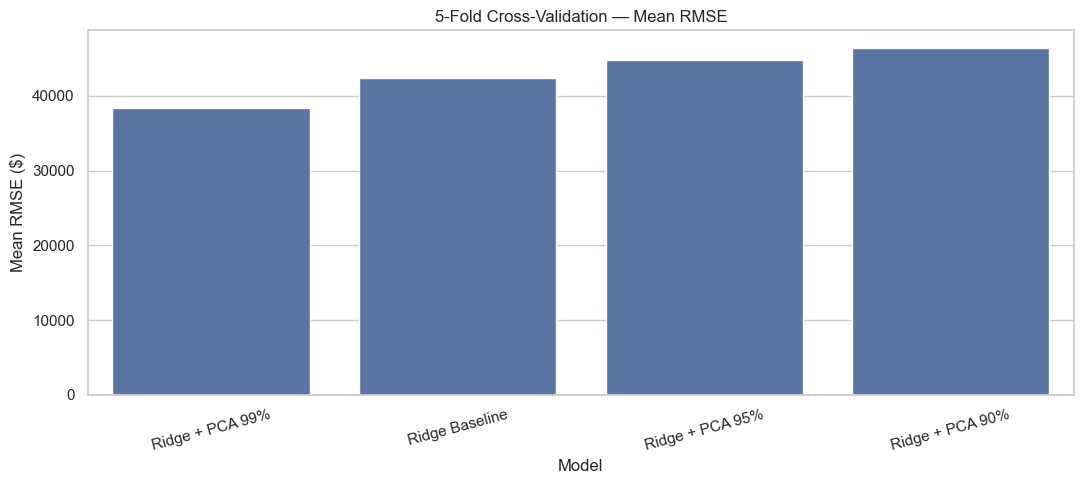

In [32]:
plt.figure(figsize=(11, 5))

sns.barplot(data=cv_results_df.sort_values('Mean RMSE'), x='Model', y='Mean RMSE')

plt.title('5-Fold Cross-Validation — Mean RMSE')
plt.xlabel('Model')
plt.ylabel('Mean RMSE ($)')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### Cross-Validation Results — Findings

Five-fold cross-validation was performed to compare Ridge Regression with and without PCA.

Ridge + PCA 99% achieved the lowest mean RMSE ($38,297.11) and the highest mean R² (0.7007).

The Ridge baseline achieved a higher mean RMSE ($42,356.58), but a slightly lower mean MAE ($17,362.80 versus $17,646.39).

These results indicate that model rankings depend on the evaluation metric.

All configurations showed substantial variation in RMSE and R² across folds.

The high standard deviations suggest that predictive performance is sensitive to the particular data split.

Although PCA 99% performed best in terms of mean cross-validation RMSE, the observed variability prevents a strong conclusion that it consistently outperforms the baseline.

Further investigation of fold-level performance is needed before selecting a final model.

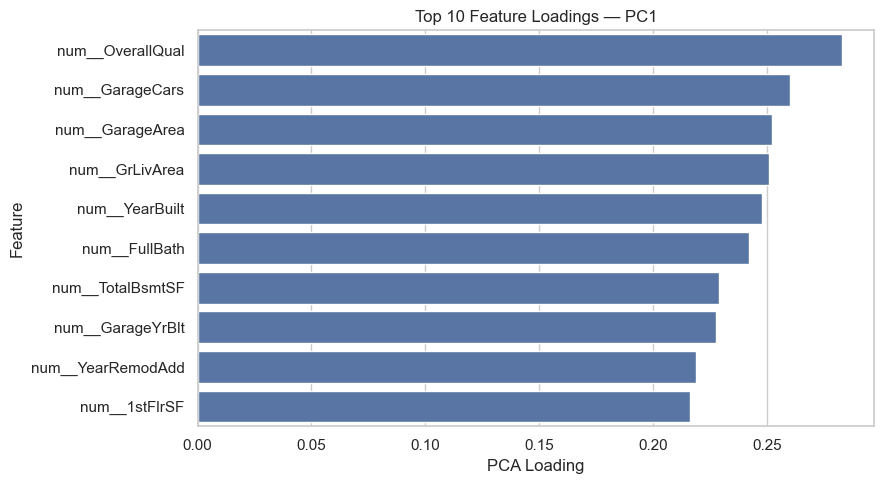

In [36]:
feature_names = preprocessor.get_feature_names_out()

pc1_loadings = pd.Series(pca_full.components_[0], index=feature_names)

top_pc1 = pc1_loadings.reindex(pc1_loadings.abs().sort_values(ascending=False).head(10).index)

plt.figure(figsize=(9, 5))

sns.barplot(x=top_pc1.values, y=top_pc1.index)

plt.title('Top 10 Feature Loadings — PC1')
plt.xlabel('PCA Loading')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## Conclusion

This project investigated the impact of Principal Component Analysis (PCA) on house price prediction.

After preprocessing, the original 79 features were transformed into 299 numerical features.

PCA successfully reduced the feature space:

- **90% explained variance:** 53 components
- **95% explained variance:** 78 components
- **99% explained variance:** 136 components

Ridge Regression was evaluated with and without PCA.

On the validation set, the Ridge baseline achieved the best performance, with an RMSE of $24,228.64 and an R² of 0.9235.

However, five-fold cross-validation showed that Ridge + PCA 99% achieved the lowest mean RMSE of $38,297.11, compared with $42,356.58 for the baseline.

Cross-validation results also showed substantial variability across folds, indicating that model performance was sensitive to the data split.

### Key Takeaway

PCA significantly reduced dimensionality, but its impact on predictive performance depended on the evaluation method and number of retained components.

The results demonstrate that **dimensionality reduction does not automatically improve prediction accuracy**.

The findings highlight the trade-off between dimensionality reduction and predictive accuracy. No single configuration consistently dominated across all evaluation metrics.